# 11 · Was liegt eigentlich auf der Platte?

**NHyDB-0.28.2-Notebook-Reihe · v1**

Die Adresse eines Werts braucht keine Tabelle – der Wert selbst aber braucht einen sorgfältig gebauten Speichercontainer. Dieses Notebook öffnet die Kiste: die Dateien einer Datenbank, die Append-only-Datei, die Commit-Grenze, was nach einem Absturz passiert, wie die Engine sich selbst prüft und wie Backups funktionieren.

> **Für wen ist das?** Dieses Notebook beginnt mit einer kurzen Einführung und geht dann in ausführbare Beispiele über. **Neu bei NHyDB?** Lies von oben nach unten – jede Idee wird eingeführt, bevor sie verwendet wird. **Kennst du die Grundlagen schon?** Überspringe die mit 📘 *Hintergrund* markierten Abschnitte und springe zu den mit ▶ markierten Experimenten. Alle Zellen laufen von oben nach unten; optionale Vertiefungen sind mit ⏩ *Vertiefung* markiert.

**Was du lernst**

* welche Dateien zu einer Datenbank gehören und was die Sperrdatei tut
* warum die Datendatei nur wächst (Append-only) und wie die Kompaktierung sie bei Bedarf verkleinert
* was die **Commit-Grenze** ist – und warum ein unterbrochener Schreibvorgang nie committete Daten beschädigt
* wie `inspect_tail`, `repair_file`, `verify`, `health` und `stats` in die Datei hineinschauen
* wie du eine Datenbank richtig sicherst, wiederherstellst und kopierst

**Vorher empfohlen:** [02 · Von der Mathematik zu gespeicherten Werten](02_from_address_to_data_v1.ipynb).

### Einrichtung

Die nächste Zelle prüft die Umgebung und definiert ein paar kleine Zeichenhilfen für dieses
Notebook. Sie ist eingeklappt, weil es darin nicht um NHyDB selbst geht – du kannst sie aber
gern öffnen. Jede Datenbank in diesem Notebook liegt in einem temporären Ordner, der am Ende
gelöscht wird.

In [1]:
import math
import os
import shutil
import sys
import tempfile

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

import nhydb

# --- environment check ---------------------------------------------------------
EXPECTED = "0.28.2"
print(f"Python {sys.version.split()[0]} · nhydb {nhydb.ENGINE_VERSION} · "
      f"file format {nhydb.FILE_FORMAT_VERSION} · matplotlib {matplotlib.__version__}")
if nhydb.ENGINE_VERSION != EXPECTED:
    print(f"⚠ This notebook was written for NHyDB {EXPECTED}; results may differ.")

# --- a private temporary folder for all databases of this notebook --------------
WORKDIR = tempfile.mkdtemp(prefix="nhydb_notebook_")


def db_path(name):
    """Path of a new database file inside the temporary folder."""
    return os.path.join(WORKDIR, name)


def cleanup():
    shutil.rmtree(WORKDIR, ignore_errors=True)


def file_sizes(path):
    """Sizes of the files that belong to a database (bytes)."""
    folder, base = os.path.split(path)
    return {f: os.path.getsize(os.path.join(folder, f))
            for f in sorted(os.listdir(folder)) if f.startswith(base)}


# --- one visual language for the whole series -----------------------------------
# Layer A (mathematical address space) = blue tones, layer B (logical data model) =
# green, layer C (storage engine) = slate grey. Lanes and boundary points belong to A.
COLORS = {
    "A": "#1d4ed8", "A_light": "#dbeafe",
    "B": "#15803d", "B_light": "#dcfce7",
    "C": "#475569", "C_light": "#e2e8f0",
    "NL": "#2563eb", "NR": "#7c3aed",
    "GZ": "#dc2626", "N0": "#9ca3af",
    "attention": "#ea580c", "ok": "#16a34a", "bad": "#dc2626",
}
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})


def plot_path(ax, steps, title=None):
    """'From input to value': boxes coloured by layer A/B/C, connected by arrows.

    ``steps`` is a list of (layer, heading, text) with layer in {"A", "B", "C"}.
    """
    n = len(steps)
    width, gap = 1.0, 0.35
    for i, (layer, head, text) in enumerate(steps):
        x = i * (width + gap)
        ax.add_patch(FancyBboxPatch((x, 0), width, 1, boxstyle="round,pad=0.02,rounding_size=0.06",
                                    facecolor=COLORS[layer + "_light"], edgecolor=COLORS[layer], lw=1.6))
        ax.text(x + width / 2, 0.80, head, ha="center", va="center", fontsize=8.5,
                fontweight="bold", color=COLORS[layer])
        ax.text(x + width / 2, 0.40, text, ha="center", va="center", fontsize=8, color="#111827",
                wrap=True)
        if i < n - 1:
            ax.annotate("", xy=(x + width + gap - 0.02, 0.5), xytext=(x + width + 0.02, 0.5),
                        arrowprops=dict(arrowstyle="-|>", color="#334155", lw=1.3))
    ax.set_xlim(-0.1, n * (width + gap) - gap + 0.1)
    ax.set_ylim(-0.35, 1.15)
    ax.axis("off")
    for j, (layer, name) in enumerate([("A", "A · address space"), ("B", "B · data model"),
                                       ("C", "C · storage engine")]):
        ax.text(j * 1.6, -0.25, "■ " + name, color=COLORS[layer], fontsize=8.5, fontweight="bold")
    if title:
        ax.set_title(title)

import json
import pandas as pd

import re


def short(e):
    # exception text without temporary folder paths
    return type(e).__name__ + ": " + re.sub(r"(/[^\s/]+)+/", "", str(e))


ROLE = {".nhydb": "data (append-only container, not encrypted)",
        ".layout.enc": "layout plan (schema), encrypted",
        ".layout.key": "key for the layout plan – keep it safe!",
        ".lock": "writer lock (empty)"}


def role(filename, base):
    rest = filename[len(base):]
    return ROLE.get(rest or ".nhydb", "backup / other")

Python 3.14.5 · nhydb 0.28.2 · file format 0.28.2 · matplotlib 3.11.2


## 📘 Hintergrund: ein Container, an den nur angehängt wird

Eine NHyDB-Datendatei hat einen festen Anfang – **zwei Superblöcke**, die sagen, wo der letzte
gültige Commit endet –, gefolgt von **Blöcken**: dichten Datensatzblöcken, losen Zellblöcken,
Indexblöcken, Systemblöcken. Neue Daten werden immer am Ende **angehängt**. Nichts, was schon
committet ist, wird je an Ort und Stelle überschrieben.

Das ergibt zwei sehr nützliche Eigenschaften:

* ein unterbrochener Schreibvorgang kann nur das **Ende** der Datei beschädigen – nie committete Daten,
* jede Änderung ist ein neuer Zustand; der alte Zustand bleibt in der Datei, bis du sie **kompaktierst**.

Die mathematische Zahl `N` einer Zelle hat nichts mit ihrer Byteposition in der Datei zu tun
(Schicht A gegenüber Schicht C). Die Engine findet den Block einer Zelle über ihr
**Blockverzeichnis**: Bei einer kleinen Datei wird es beim Öffnen im Arbeitsspeicher aufgebaut;
größere Datenbanken halten es zusätzlich in der Datei (`DIRECTORY`-Blöcke), damit das Öffnen nicht
jeden Block lesen muss.

## 1 · Die Dateien einer Datenbank

**Frage:** Was genau wird auf der Platte angelegt?

▶ **Ausprobieren:** eine kleine Datenbank mit 100 Messdatensätzen.

In [2]:
PATH = db_path("station.nhydb")
BASE = os.path.basename(PATH)

with nhydb.create(PATH) as db:
    db.create_realm(1, "station")
    db.create_shape(1, 1, "reading", [{"v": 1, "name": "label", "type": "utf8"},
                                      {"v": 2, "name": "value", "type": "f64"}])
    db.create_classic_layout(1, 1, "readings", shape_id=1)
    db.put_dense_batch(1, 1, [[f"v1-{u:03d}", u * 0.5] for u in range(1, 101)], shape_id=1)

files = pd.DataFrame([{"file": f, "bytes": b, "role": role(f, BASE)} for f, b in file_sizes(PATH).items()])
files.set_index("file")

,bytes,role
file,,
station.nhydb,11064,"data (append-only container, not encrypted)"
station.nhydb.layout.enc,1422,"layout plan (schema), encrypted"
station.nhydb.layout.key,160,key for the layout plan – keep it safe!
station.nhydb.lock,0,writer lock (empty)


**Immer nur ein Schreiber.** Beim Öffnen einer Datenbank wird eine exklusive Sperre auf `<db>.lock`
gesetzt – auch zum Lesen. Ein zweites geöffnetes Objekt (in diesem oder einem anderen Prozess)
wird abgewiesen:

In [3]:
with nhydb.open(PATH) as db:
    try:
        nhydb.open(PATH)
    except nhydb.DatabaseLockedError as e:
        print("second open →", short(e))
        locked = True
assert locked
with nhydb.open(PATH) as db:                      # after closing, the lock is free again
    print("reopened after close:", db.get_value(1, 1, 1))

second open → DatabaseLockedError: database is already being written by another process (lock station.nhydb.lock not acquired after 0 ms)
reopened after close: v1-001


## 2 · Append-only: Jede Änderung ist ein neuer Zustand

**Frage:** Was passiert mit der Datei, wenn wir alle 100 Datensätze immer wieder überschreiben?

▶ **Ausprobieren:** fünf Runden, in denen jeder Datensatz überschrieben wird (jede Runde ein
Commit), danach wird die Hälfte der Datensätze gelöscht. Nach jedem Schritt messen wir die Datei
und prüfen, ob der allererste Wert `v1-005` noch physisch in den Bytes der Datei steht.

In [4]:
ROUNDS = 5                                            # ▶ Try it: number of overwrite rounds


def contains(path, text):
    with open(path, "rb") as f:
        return text.encode() in f.read()


steps = [{"step": "initial write", "file bytes": os.path.getsize(PATH), "live records": 100,
          "'v1-005' still in file": contains(PATH, "v1-005")}]
with nhydb.open(PATH) as db:
    for r in range(2, ROUNDS + 2):
        db.put_dense_batch(1, 1, [[f"v{r}-{u:03d}", u * 0.5 * r] for u in range(1, 101)], shape_id=1)
        db.commit()
        steps.append({"step": f"overwrite round {r - 1}", "file bytes": os.path.getsize(PATH),
                      "live records": 100, "'v1-005' still in file": contains(PATH, "v1-005")})
    for u in range(1, 101, 2):
        db.delete_record(1, u)
    db.commit()
    steps.append({"step": "delete 50 records", "file bytes": os.path.getsize(PATH), "live records": 50,
                  "'v1-005' still in file": contains(PATH, "v1-005")})
    assert db.get_record(1, 5) is None and db.get_value(1, 6, 1) == f"v{ROUNDS + 1}-006"

result = nhydb.NHyDB.compact_file(PATH, make_backup=False)       # needs the database closed
steps.append({"step": "compact_file", "file bytes": os.path.getsize(PATH), "live records": 50,
              "'v1-005' still in file": contains(PATH, "v1-005")})
growth = pd.DataFrame(steps)
print(f"compaction: {result['before_bytes']:,} → {result['after_bytes']:,} bytes, "
      f"{result['records_written']} records rewritten, verify ok: {result['verify']['ok'] if isinstance(result['verify'], dict) else result['verify']}")
growth

compaction: 22,824 → 12,456 bytes, 50 records rewritten, verify ok: True


,step,file bytes,live records,'v1-005' still in file
0,initial write,11064,100,True
1,overwrite round 1,13016,100,True
2,overwrite round 2,14968,100,True
3,overwrite round 3,16920,100,True
4,overwrite round 4,18872,100,True
5,overwrite round 5,20824,100,True
6,delete 50 records,22824,50,True
7,compact_file,12456,50,False


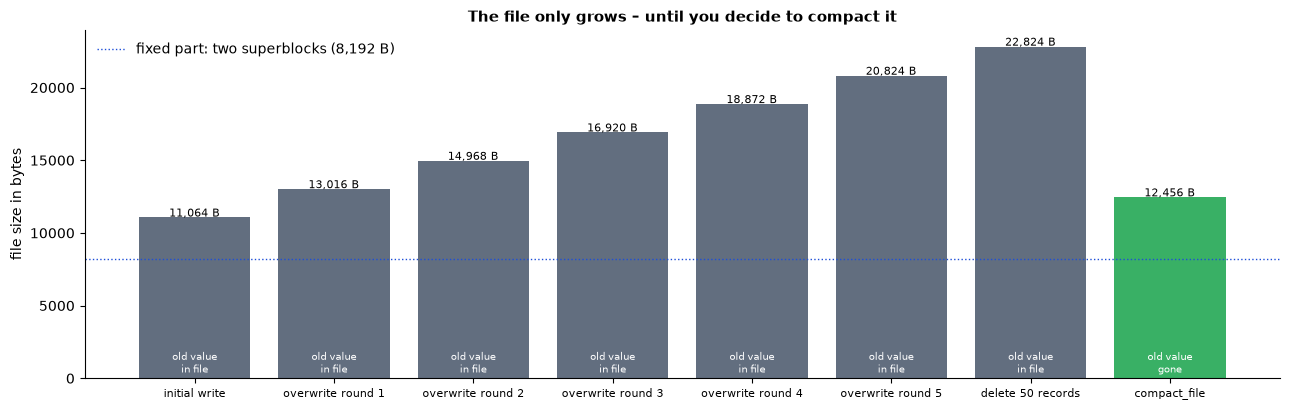

In [5]:
fig, ax = plt.subplots(figsize=(13, 4.2))
base = growth["file bytes"][0]
colors = [COLORS["C"]] * (len(growth) - 1) + [COLORS["ok"]]
bars = ax.bar(range(len(growth)), growth["file bytes"], color=colors, alpha=0.85)
for i, row in growth.iterrows():
    ax.text(i, row["file bytes"] + 60, f"{row['file bytes']:,} B", ha="center", fontsize=8)
    ax.text(i, 400, "old value\nin file" if row["'v1-005' still in file"] else "old value\ngone",
            ha="center", fontsize=7.5, color="white")
ax.axhline(8192, color=COLORS["A"], lw=1, ls=":", label="fixed part: two superblocks (8,192 B)")
ax.set_xticks(range(len(growth)))
ax.set_xticklabels(growth["step"], fontsize=8)
ax.set_ylabel("file size in bytes")
ax.set_title("The file only grows – until you decide to compact it")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

**Was ist passiert?**

* Jede Überschreibrunde hat etwa 2 KB angehängt: die neuen Versionen der Datensätze. Das Löschen
  hat *Tombstones* (Markierungen „dieser Datensatz ist weg“) angehängt – die Datei ist
  wieder gewachsen, obwohl Daten entfernt wurden.
* Der erste Wert `v1-005` blieb die ganze Zeit physisch in der Datei. Lesen liefert immer den
  **neuesten** Zustand; ältere Zustände werden einfach nicht mehr referenziert.
* `compact_file` hat nur den lebenden Zustand in einen frischen Container geschrieben: Die Datei
  ist geschrumpft, und die alten Versionen sind verschwunden. NHyDB kompaktiert nie automatisch –
  **du** entscheidest, wann (zum Beispiel nach vielen Löschungen). **Ah – Append-only heißt: Nichts
  wird überschrieben, alles wird beim Commit entschieden.**

## 3 · Die Commit-Grenze

**Frage:** Wann sind Daten wirklich sicher?

Schreibvorgänge landen zuerst am Ende der Datei. Erst `commit()` verschiebt die **Commit-Grenze**
(und schreibt sie in einen Superblock). Beim Öffnen der Datenbank wird alles **hinter** der Grenze
abgeschnitten. `committed_end` ist die Grenze, `last_valid_end` das Ende von allem, was bisher
geschrieben wurde.

▶ **Ausprobieren:** drei Batches mit Commit, einer ohne – dann wird die Datenbank *ohne* Commit
geschlossen, genau wie bei einem Absturz.

In [6]:
CRASH = db_path("crash.nhydb")
timeline = []
db = nhydb.create(CRASH)
db.create_realm(1, "r")
db.create_shape(1, 1, "s", [{"v": 1, "name": "t", "type": "utf8"}])
db.create_classic_layout(1, 1, "c", shape_id=1)
db.commit()
timeline.append(("schema + commit", db.committed_end, db.last_valid_end))
for k in (1, 2, 3):
    db.put_dense_batch(1, 1, [[f"batch{k}-{u}"] for u in range(1, 101)])
    if k < 3:
        db.commit()
        timeline.append((f"batch {k} + commit", db.committed_end, db.last_valid_end))
    else:
        db.sync()                                     # bytes are in the file, but not committed
        timeline.append((f"batch {k}, NO commit", db.committed_end, db.last_valid_end))
db.close(commit=False)                                # like a crash before the commit

with nhydb.open(CRASH) as db:
    recovered = db.recovered_tail_bytes
    value = db.get_value(1, 5, 1)
print(f"after reopening: {recovered} uncommitted bytes were cut off; record 5 = {value!r}")
assert recovered == timeline[-1][2] - timeline[-1][1] and value == "batch2-5"
pd.DataFrame(timeline, columns=["step", "committed_end", "last_valid_end"])

after reopening: 1440 uncommitted bytes were cut off; record 5 = 'batch2-5'


,step,committed_end,last_valid_end
0,schema + commit,9096,9096
1,batch 1 + commit,10536,10536
2,batch 2 + commit,11976,11976
3,"batch 3, NO commit",11976,13416


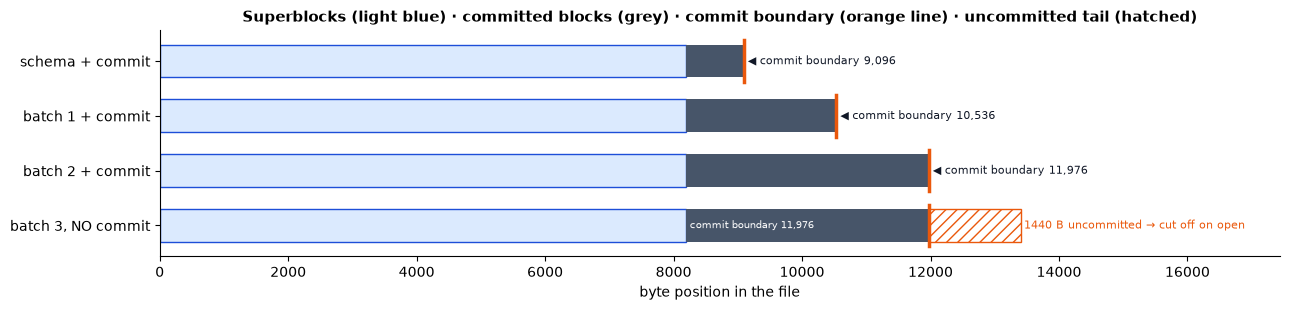

In [7]:
fig, ax = plt.subplots(figsize=(13, 3.2))
for i, (step, committed, written) in enumerate(timeline):
    y = len(timeline) - 1 - i
    ax.barh(y, 8192, color=COLORS["A_light"], edgecolor=COLORS["A"], height=0.6)
    ax.barh(y, committed - 8192, left=8192, color=COLORS["C"], height=0.6)
    if written > committed:
        ax.barh(y, written - committed, left=committed, color="white", edgecolor=COLORS["attention"],
                hatch="///", height=0.6)
        ax.text(written + 40, y, f"{written - committed} B uncommitted → cut off on open",
                va="center", fontsize=8, color=COLORS["attention"])
    ax.plot([committed, committed], [y - 0.38, y + 0.38], color=COLORS["attention"], lw=2.5)
    if written > committed:
        ax.text(8192 + 60, y, f"commit boundary {committed:,}", va="center", fontsize=7.5, color="white")
    else:
        ax.text(committed + 60, y, f"◀ commit boundary {committed:,}", va="center", fontsize=8,
                color="#111827")
ax.set_yticks(range(len(timeline)))
ax.set_yticklabels([t[0] for t in reversed(timeline)])
ax.set_xlabel("byte position in the file")
ax.set_xlim(0, timeline[-1][2] * 1.3)
ax.set_title("Superblocks (light blue) · committed blocks (grey) · commit boundary (orange line) · uncommitted tail (hatched)")
plt.tight_layout()
plt.show()

**Was ist passiert?** Der dritte Batch hat die Datei erreicht, aber die Commit-Grenze zeigte noch
auf das Ende von Batch 2. Beim nächsten Öffnen hat die Engine das Ende abgeschnitten – die Datenbank
ist genau im Zustand des letzten Commits. **Ah – ein Absturz kann die nicht committete Arbeit
kosten, nie die committeten Daten.**

## 4 · Beschädigte Dateien: untersuchen, reparieren, verweigern

**Frage:** Was ist, wenn am Ende der Datei Müll steht oder committete Daten fehlen?

▶ **Ausprobieren** – ausschließlich an **Kopien**. Fall A: ein unvollständiger Schreibvorgang am
Ende (simuliert durch angehängte Bytes). Fall B: Die Datei wurde *innerhalb* committeter Daten
abgeschnitten (zum Beispiel durch eine fehlerhafte Kopie).

In [8]:
def copy_db(src, folder):
    os.makedirs(folder, exist_ok=True)
    dst = os.path.join(folder, os.path.basename(src))
    for suffix in ("", ".layout.enc", ".layout.key"):
        shutil.copy2(src + suffix, dst + suffix)
    return dst


# Case A: garbage after the last commit
case_a = copy_db(CRASH, os.path.join(WORKDIR, "case_a"))
with open(case_a, "ab") as f:
    f.write(b"NHBL" + b"\x07" * 40)                  # looks like the start of a block, but is incomplete
tail = nhydb.NHyDB.inspect_tail(case_a)
print("A inspect_tail:", {k: tail[k] for k in ("clean", "trailing_bad_bytes", "error")})
report = nhydb.NHyDB.repair_file(case_a)             # apply=False: only a report
print("A repair_file (report only): clean =", report["clean"])
applied = nhydb.NHyDB.repair_file(case_a, apply=True, make_backup=False)
print("A repair_file(apply=True): applied =", applied["applied"], "→ clean =", nhydb.NHyDB.inspect_tail(case_a)["clean"])
with nhydb.open(case_a) as db:
    assert db.get_value(1, 5, 1) == "batch2-5"
    print("A data after repair:", db.get_value(1, 5, 1))

# Case B: committed data is missing
case_b = copy_db(CRASH, os.path.join(WORKDIR, "case_b"))
with open(case_b, "r+b") as f:
    f.truncate(os.path.getsize(case_b) - 30)
print("\nB inspect_tail:", {k: nhydb.NHyDB.inspect_tail(case_b)[k] for k in ("clean", "last_good_end", "error")})
try:
    nhydb.open(case_b)
    refused = False
except nhydb.CorruptionError as e:
    refused = True
    print("B open →", short(e))
assert refused

A inspect_tail: {'clean': False, 'trailing_bad_bytes': 44, 'error': 'block header magic/version/type invalid'}
A repair_file (report only): clean = False
A repair_file(apply=True): applied = True → clean = True
A data after repair: batch2-5

B inspect_tail: {'clean': False, 'last_good_end': 10536, 'error': 'Block 5: payload incomplete'}
B open → CorruptionError: newest superblock (slot 0, generation 4) points to commit boundary 11976 outside the file (11946 bytes; file truncated?). The commit boundary is ambiguous: the 1410 bytes after the boundary 10536 of the usable superblock (generation 3) may contain committed data. Nothing was changed. Open with readonly=True to read the state of the usable superblock, or run repair_file() with keep_uncommitted=True (keep these blocks) or allow_data_loss=True (discard them)


**Was ist passiert?** Ein beschädigtes **Ende** hinter der Commit-Grenze ist harmlos: Es wird
gemeldet und abgeschnitten (automatisch beim Öffnen oder ausdrücklich mit `repair_file(apply=True)`).
Fehlende **committete** Daten sind etwas anderes: Die Engine verweigert das Öffnen der Datei
(*fail closed*), statt zu raten, und die Meldung nennt die Möglichkeiten – den letzten eindeutigen
Zustand mit `readonly=True` lesen oder mit `repair_file` ausdrücklich entscheiden, ob die Blöcke
dahinter behalten oder verworfen werden. `repair_file` erfindet nie Daten – sind committete Daten
verloren, stelle die Datei aus einem Backup wieder her (Abschnitt 7).

## 5 · Ein Blick hinein: Blöcke, health und verify

**Frage:** Woraus besteht die Datei?

`stats()` meldet den Speicher nach Blocktyp; `verify` prüft die Blockstruktur (mit `deep=True`
auch jede Prüfsumme der Nutzdaten); `health` führt eine Liste von Konsistenzprüfungen aus.

In [9]:
with nhydb.open(PATH) as db:
    db.create_index(1, 1, "by_label", "label")
    db.build_indexes()
    db.checkpoint()                                   # writes a CHECKPOINT block and commits
    st = db.stats()
    health = db.health(deep=True)
    verify = db.verify(deep=True)

blocks = st["storage"]["by_block_type"]
print("superblocks:", st["storage"]["superblocks_bytes"], "bytes")
print(pd.DataFrame(blocks).T[["blocks", "bytes", "payload_bytes"]])
print("\nhealth:", health["status"], {c["name"]: c["status"] for c in health["checks"]})
print("verify:", "ok" if verify["ok"] else "errors", f"– {verify['scanned_blocks']} blocks, {verify['error_count']} errors")
assert verify["ok"] and health["status"] == "healthy"

superblocks: 8192 bytes
                 blocks  bytes  payload_bytes
CHECKPOINT            2    376            306
DATA_DENSE           50   3600           1750
SECONDARY_INDEX       1    256            219
SYSTEM_R0_U1          2    816            743

health: healthy {'container': 'ok', 'layouts': 'ok', 'spacemap': 'ok', 'layout_routing': 'ok', 'math_layouts': 'ok', 'definitions': 'ok', 'indexes': 'ok', 'checkpoint': 'ok'}
verify: ok – 55 blocks, 0 errors


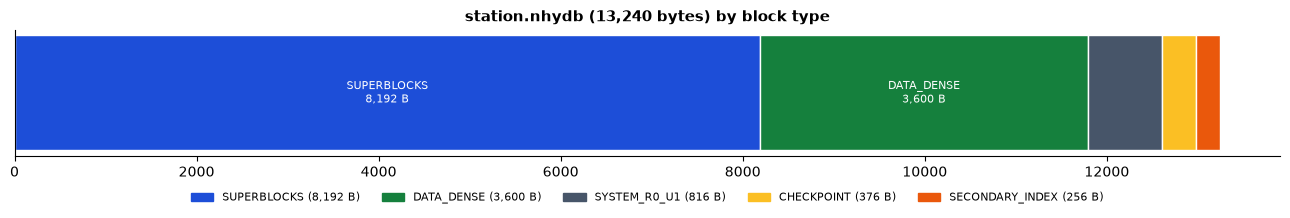

In [10]:
parts = [("SUPERBLOCKS", st["storage"]["superblocks_bytes"])] + sorted(
    ((k, v["bytes"]) for k, v in blocks.items()), key=lambda kv: -kv[1])
palette = {"SUPERBLOCKS": COLORS["A"], "DATA_DENSE": COLORS["B"], "SPARSE_CELLS": "#4ade80",
           "SYSTEM_R0_U1": COLORS["C"], "DB_CONFIG": "#94a3b8", "SECONDARY_INDEX": COLORS["attention"],
           "CHECKPOINT": "#fbbf24"}
fig, ax = plt.subplots(figsize=(13, 2.4))
left = 0
for name, size in parts:
    ax.barh(0, size, left=left, color=palette.get(name, "#cbd5e1"), edgecolor="white")
    if size / sum(s for _, s in parts) > 0.09:
        ax.text(left + size / 2, 0, f"{name}\n{size:,} B", ha="center", va="center", fontsize=8, color="white")
    left += size
handles = [Rectangle((0, 0), 1, 1, color=palette.get(n, "#cbd5e1")) for n, _ in parts]
ax.legend(handles, [f"{n} ({s:,} B)" for n, s in parts], ncol=5, frameon=False, fontsize=8,
          loc="upper center", bbox_to_anchor=(0.5, -0.2))
ax.set_yticks([])
ax.set_title(f"station.nhydb ({left:,} bytes) by block type")
plt.tight_layout()
plt.show()

**Was ist passiert?** Nach der Kompaktierung besteht die Datei aus den beiden Superblöcken, einigen
Systemblöcken (die Identität in R0,u1 – Abschnitt 6), den dichten Datensätzen, einem kleinen
Indexblock und dem Checkpoint. Die 50 verbliebenen Datensätze liegen bei jedem zweiten `u` (die
ungeraden wurden gelöscht), deshalb werden sie als 50 kleine dichte Segmente geschrieben – ein
zusammenhängender Bereich bräuchte weit weniger Blöcke. `health` meldet `healthy`, weil ein
Checkpoint existiert und alle Prüfungen bestanden sind.

## 6 · Die Identität einer Datenbank: R0,u1

Jede Datenbank speichert ihre Identität in einem reservierten Systembereich, den Zellen `(0, 1, v)`:
Datenbank-ID, Dateinamen, Schema-Generation und Hash, Erstellungszeit, Verschlüsselungsverfahren
und die festen Konstanten. Realm 0 ist kein Dynadron-Realm für Nutzerdaten – er ist das eigene
Typenschild der Engine. Notebook 12 zeigt, wie er die Datendatei an ihren Layoutplan bindet.

In [11]:
LABELS = {1: "database id (UUID)", 2: "original file name", 3: "layout plan file", 4: "key file name",
          5: "plan generation", 6: "schema digest (HMAC)", 7: "created (ns)", 8: "encryption scheme",
          9: "fixed constants"}
with nhydb.open(PATH) as db:
    meta = db.get_system_metadata()
system = pd.DataFrame([{"cell": f"R0,u1,v{v}", "meaning": LABELS[v],
                        "value": str(meta["cells"][str(v)])[:70]} for v in range(1, 10)])
system.set_index("cell")

,meaning,value
cell,,
"R0,u1,v1",database id (UUID),abb34299-4ae6-4c2e-9bd2-464d24ed7d7d
"R0,u1,v2",original file name,station.nhydb
"R0,u1,v3",layout plan file,station.nhydb.layout.enc
"R0,u1,v4",key file name,station.nhydb.layout.key
"R0,u1,v5",plan generation,2
"R0,u1,v6",schema digest (HMAC),1f2a7c7d76aa92c16cee86f34fb814cc2b951ba1998af4...
"R0,u1,v7",created (ns),1794414782179599000
"R0,u1,v8",encryption scheme,AES-256-GCM + HMAC-SHA256
"R0,u1,v9",fixed constants,"{'lane_NL': 0, 'lane_NR': 1, 'realm_span': 100..."


## 7 · Backup, Wiederherstellung und Kopien

**Regeln** (Cookbook-Abschnitt 21):

* sichere **alle drei Dateien** (`.nhydb`, `.layout.enc`, `.layout.key`), während die Datenbank
  **geschlossen** ist;
* stelle unter **demselben Dateinamen** wieder her (ein anderer Ordner ist in Ordnung) – der
  Dateiname ist Teil der Identität;
* für eine Kopie unter neuem Namen nimm `compact_file(path, output=new_path)`.

In [12]:
backup = copy_db(PATH, os.path.join(WORKDIR, "backup"))              # 1. backup (database closed)
restored = copy_db(backup, os.path.join(WORKDIR, "restored"))        # 2. restore elsewhere
with nhydb.open(restored) as db:
    print("restored copy opens:", db.get_value(1, 6, 1))

renamed = os.path.join(os.path.dirname(restored), "renamed.nhydb")   # 3. a renamed data file ...
os.rename(restored, renamed)
try:
    nhydb.open(renamed, layout_path=restored + ".layout.enc", key_path=restored + ".layout.key")
    rejected = False
except nhydb.CorruptionError as e:
    rejected = True
    print("renamed file →", short(e))
assert rejected

copy = os.path.join(WORKDIR, "copies", "station_copy.nhydb")        # 4. ... the right way
os.makedirs(os.path.dirname(copy), exist_ok=True)
nhydb.NHyDB.compact_file(PATH, output=copy)
with nhydb.open(copy) as db:
    meta_copy = db.get_system_metadata()["cells"]
    print("copy under new name opens:", db.get_value(1, 6, 1), "| own id:", meta_copy["1"] != meta["cells"]["1"])
print(sorted(os.listdir(os.path.dirname(copy))))

restored copy opens: v6-006
renamed file → CorruptionError: DB file name 'renamed.nhydb' does not match the name 'station.nhydb' bound in R0,u1: the database file must keep the name it was created with (rename it back, or create a copy under a new name with compact_file(output=...))
copy under new name opens: v6-006 | own id: True
['station_copy.nhydb', 'station_copy.nhydb.layout.enc', 'station_copy.nhydb.layout.key', 'station_copy.nhydb.lock']


**Was ist passiert?** Die wiederhergestellte Kopie ließ sich öffnen, weil die Namen noch zur in
R0,u1 gespeicherten Identität passen. Die umbenannte Datei wurde abgewiesen: Der Name in der Datei
und der Name auf der Platte unterscheiden sich. Die kompaktierte Kopie ist eine neue Datenbank mit
**eigener** ID und eigenen Plan- und Schlüsseldateien.

## Jetzt du

**Aufgabe:** Wie viele Bytes kostet eine Überschreibrunde von 100 Datensätzen im Durchschnitt?
Berechne es aus der Tabelle `growth` in Abschnitt 2 und vergleiche es mit der Größe der
kompaktierten Datei.

In [13]:
rounds = growth[growth["step"].str.startswith("overwrite")]
per_round = rounds["file bytes"].diff().dropna().mean() if len(rounds) > 1 else rounds["file bytes"].iloc[0] - growth["file bytes"][0]
print(f"one overwrite round ≈ {per_round:,.0f} bytes  (≈ {per_round / 100:.1f} bytes per record)")
print(f"compacted file: {growth['file bytes'].iloc[-1]:,} bytes for 50 live records")
assert per_round > 0

one overwrite round ≈ 1,952 bytes  (≈ 19.5 bytes per record)
compacted file: 12,456 bytes for 50 live records


## ⏩ Vertiefung: auf die Sperre warten, Dauerhaftigkeit

Ein zweiter Prozess kann auf die Sperre **warten**, statt zu scheitern (`lock_timeout_ms`). Der
Dauerhaftigkeitsmodus bestimmt, wie gründlich ein Commit synchronisiert: `"fsync"` (Standard) oder
`"full"` (leert unter macOS zusätzlich den Cache des Laufwerks).

In [14]:
import subprocess
import textwrap

holder = textwrap.dedent('''
    import sys, time, nhydb
    db = nhydb.open(sys.argv[1])
    print("locked", flush=True)
    time.sleep(1.0)
    db.close()
''')
proc = subprocess.Popen([sys.executable, "-c", holder, PATH], stdout=subprocess.PIPE, text=True)
assert proc.stdout.readline().strip() == "locked"
try:
    nhydb.open(PATH)
except nhydb.DatabaseLockedError:
    print("other process holds the lock → DatabaseLockedError")
db = nhydb.open(PATH, lock_timeout_ms=10_000)          # waits until the other process closes
print("opened after waiting; durability =", db.durability)
db.close()
proc.wait(timeout=30)
proc.stdout.close()

other process holds the lock → DatabaseLockedError


opened after waiting; durability = fsync


## Zusammenfassung

* Eine Datenbank besteht aus drei zusammengehörenden Dateien (+ der Sperrdatei); nur der Layoutplan ist verschlüsselt.
* Die Datendatei ist Append-only: Überschreiben und Löschen fügen neue Zustände hinzu; `compact_file` entfernt alte bei Bedarf.
* Nur committete Daten zählen: Ein nicht committetes oder beschädigtes Ende wird abgeschnitten, fehlende committete Daten werden verweigert.
* `stats`, `verify`, `health`, `inspect_tail` und `repair_file` schauen in den Container; R0,u1 enthält seine Identität.
* Sichere alle drei Dateien im geschlossenen Zustand; stelle unter demselben Namen wieder her; kopiere mit `compact_file(output=…)`.

## Wie es weitergeht

* [12 · Ein Layoutplan, zwei Ansichten](12_encrypted_layout_and_key_v1.ipynb) – wie Plan und Schlüssel das Schema schützen.
* [13 · Benchmark-Labor](13_benchmark_lab_v1.ipynb) – was Commits und Dauerhaftigkeit kosten.

**Cookbook-Abschnitte:** 5 (Commit, Sync, Schließen), 20 (Wartung), 21 (Dateien, Backup), 22 (Sperren), 23 (R0,u1) im [NHyDB Python Cookbook](https://github.com/nhydb-run4/NHyDB/blob/main/docs/cookbook/PYTHON_COOKBOOK.md).

In [15]:
# Clean up: remove the temporary folder with all databases of this notebook.
cleanup()
print("Temporary files removed.")

Temporary files removed.
